<a href="https://colab.research.google.com/github/Hermann-CC96/IA-Computacional/blob/main/Trabalho_1_(Regressao).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Problema - A tarefa desse conjunto de dados é prever o volume de tráfego espaço-temporal com base no volume de tráfego histórico e em outros recursos em locais vizinhos.

Importar Biblitecas

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
CaminhoArquivo = '/content/drive/MyDrive/IA COMPUTACIONAL/dataframe/winequality-white.csv'

In [ ]:
dados =  pd.read_csv(CaminhoArquivo, delimiter =';')

In [ ]:
dados.head(10)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
5,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
6,6.2,0.32,0.16,7.0,0.045,30.0,136.0,0.9949,3.18,0.47,9.6,6
7,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
8,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
9,8.1,0.22,0.43,1.5,0.044,28.0,129.0,0.9938,3.22,0.45,11.0,6


**Regressão - Previsão de Fluxo de Tráfego**

Regressão - Previsão de Qualidade de Vinhos
Dataset: Qualidade de Vinho Branco(winequality-write.csv)

Origem: UCI Machine Learning Repository * Problema: Regressão

Objetivo: O objetivo deste problema é prever o valor numérico da coluna "quality" (qualidade do vinho), que é uma nota sensorial.

Atributos: O dataset possui 11 features (atributos) que são medições físico-químicas, como "fixed acidity", "citric acid", "residual sugar", etc.

Rótulo (Alvo): A variável alvo (y) é a coluna "quality".

In [ ]:
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


In [ ]:
dados.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


**Pré-processamento**:

Para preparar os dados para os modelos de regressão, os seguintes passos foram executados:

Verificação de Nulos: Uma verificação dados.isnull().sum() foi realizada. Embora o dataset informe não ter valores ausentes, esta etapa confirma a integridade dos dados.

Separação (X e y): Os dados foram divididos em features (X) e alvo (y).

Separação (Treino e Teste): O conjunto foi dividido em dados de treino e teste usando train_test_split.

Padronização: A Regressão Linear é sensível a escalas de features diferentes. Por isso, aplicamos StandardScaler (como feito em Regressão_Linear_normalização_padronização.ipynb) nos dados de treino e teste. Isso garante que todas as features tenham a mesma importância inicial para o modelo.

In [ ]:
dados.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [ ]:
# Definir X (features) e y (alvo)
y = dados['quality'].values
X = dados.drop('quality', axis=1).values

In [ ]:
#Printar as medias de desvio padrão dos feature
print(X.mean(axis=0))

[6.85478767e+00 2.78241119e-01 3.34191507e-01 6.39141486e+00
 4.57723561e-02 3.53080849e+01 1.38360657e+02 9.94027376e-01
 3.18826664e+00 4.89846876e-01 1.05142670e+01]


**Divisão Treino/Teste: Usou train_test_split com 30% dos dados para teste (test_size=0.3). Isso é crucial para testar se o modelo consegue prever dados que ele nunca viu antes.**

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
scaler = StandardScaler()

In [ ]:
X_treino = scaler.fit_transform(X_treino)
X_teste = scaler.transform(X_teste)

In [ ]:
print("Dados de Treino:")
print(X_treino)
print("\nDados de Teste:")
print(X_teste)

Dados de Treino:
[[-0.31132265 -0.28780076 -0.27645327 ... -1.13031916  0.0940735
  -1.14685943]
 [ 1.10470658 -0.18935432  1.30066456 ... -1.06354794 -1.49278025
   0.64257527]
 [-0.66532995 -0.48469365 -0.02743466 ...  0.87281754 -0.61119484
   0.56123733]
 ...
 [ 0.86870171 -0.09090788  1.54968316 ... -1.13031916  0.35854912
   0.72391321]
 [-0.66532995 -0.3862472  -0.35945947 ... -0.12875081 -0.963829
   0.07320968]
 [ 1.45871389 -0.09090788  0.13857774 ...  0.2051053   1.24013454
  -0.0894662 ]]

Dados de Teste:
[[-1.01933726  0.105985    0.63661495 ... -0.6629206   0.88750037
   0.3714488 ]
 [-1.72735188  2.4686996  -1.43854009 ...  0.07156286  0.35854912
   2.18799615]
 [ 0.27868953 -0.28780076  0.47060254 ...  0.60573264 -0.5230363
   1.37461674]
 ...
 [ 0.1606871   1.18889586 -0.69148427 ... -1.26386161  0.53486621
   0.72391321]
 [-0.07531777  0.79511009 -0.77449048 ...  0.53896142 -1.31646317
   1.6999685 ]
 [-0.66532995  1.2873423  -0.27645327 ...  2.27501322  2.65067121
  

**Modelo de Regressão Linear**

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
modelo_lr = LinearRegression()
modelo_lr.fit(X_treino, y_treino)

LinearRegression()

In [ ]:
# 1. Criar e treinar o modelo de Regressão Linear
score_lr = modelo_lr.score(X_treino, y_treino)

In [ ]:
print(f"Score (R²) da Regressão Linear: {score_lr: .4f}")

Score (R²) da Regressão Linear:  0.2866


In [ ]:
# Fazer predições para usar no gráfico
predicoes_lr = modelo_lr.predict(X_teste)

In [ ]:
plt.figure(figsize=(10, 6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

Text(0, 0.5, 'Valores Previstos')

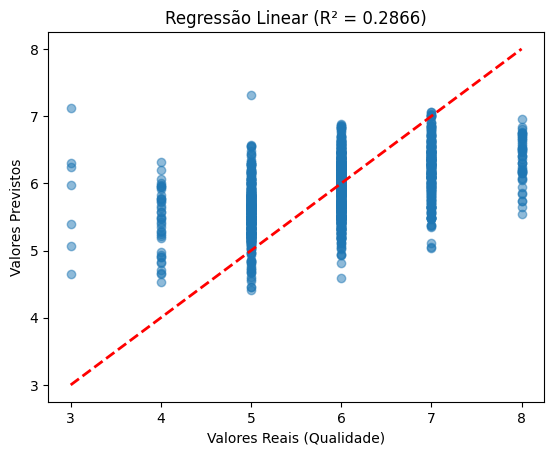

In [ ]:
# Cria o gráfico de dispersão: y_teste (Reais) vs. predicoes_lr (Previstos)
plt.scatter(y_teste, predicoes_lr, alpha=0.5)

# Adiciona a linha de referência vermelha (onde a predição seria perfeita)
plt.plot([y_teste.min(), y_teste.max()], [y_teste.min(), y_teste.max()], 'r--', lw=2)

# Adiciona títulos e rótulos
plt.title(f'Regressão Linear (R² = {score_lr:.4f})')
plt.xlabel('Valores Reais (Qualidade)')
plt.ylabel('Valores Previstos')

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
#Criar e treinar o modelo Random Forest
modelo_rf = RandomForestRegressor(n_estimators=100, random_state=42)
modelo_rf.fit(X_treino, y_treino)

RandomForestRegressor(random_state=42)

In [ ]:
#Obter o score R² (métrica de eficiência)
score_rf = modelo_rf.score(X_teste, y_teste)
print(f"Score (R²) do Random Forest: {score_rf:.4f}")

Score (R²) do Random Forest: 0.5259


In [ ]:
predicoes_rf = modelo_rf.predict(X_teste)

In [ ]:
plt.figure(figsize=(10, 6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

Text(0, 0.5, 'Valores Previstos')

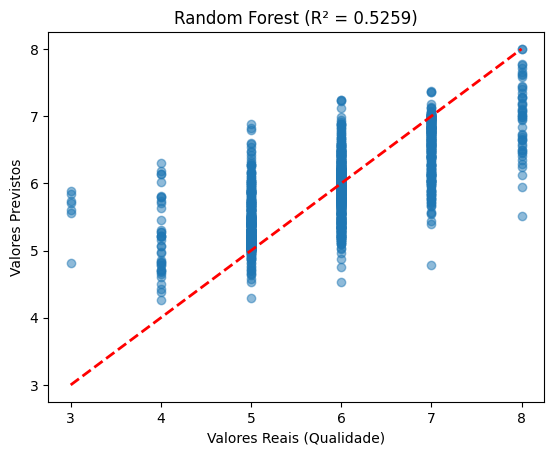

In [ ]:
plt.scatter(y_teste, predicoes_rf, alpha=0.5)
plt.plot([y_teste.min(), y_teste.max()], [y_teste.min(), y_teste.max()], 'r--', lw=2)

plt.title(f'Random Forest (R² = {score_rf:.4f})')

plt.xlabel('Valores Reais (Qualidade)')
plt.ylabel('Valores Previstos')

**Comparação de modelo Regresão Linear e modelo Random Forest**

In [ ]:
# Imprimir os scores para comparação direta
print("\n--- COMPARAÇÃO DE EFICIÊNCIA (R²) ---")
print(f"Regressão Linear: {score_lr:.4f}")
print(f"Random Forest:    {score_rf:.4f}")


--- COMPARAÇÃO DE EFICIÊNCIA (R²) ---
Regressão Linear: 0.2866
Random Forest:    0.5259


In [ ]:
plt.figure(figsize=(10, 6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>


 --- COMPORAÇÃO DE GRAFICO DE EFICIÊNCIA


Text(0, 0.5, 'Valores Previstos')

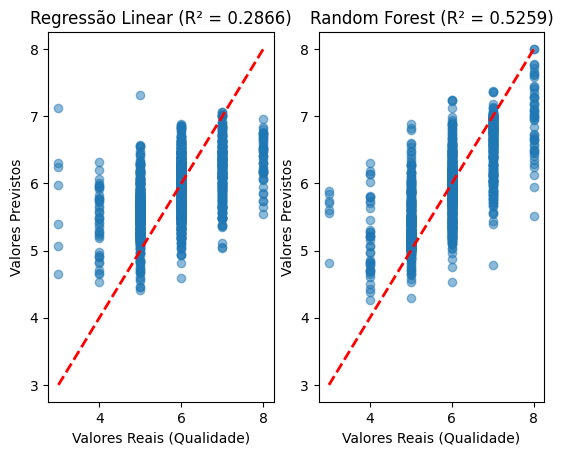

In [ ]:
print("\n --- COMPORAÇÃO DE GRAFICO DE EFICIÊNCIA")

plt.subplot(1, 2, 1)
plt.scatter(y_teste, predicoes_lr, alpha =0.5)
plt.plot([y_teste.min(), y_teste.max()], [y_teste.min(), y_teste.max()], 'r--', lw=2)
plt.title(f'Regressão Linear (R² = {score_lr:.4f})')
plt.xlabel('Valores Reais (Qualidade)')
plt.ylabel('Valores Previstos')

plt.subplot(1, 2, 2)
plt.scatter(y_teste, predicoes_rf, alpha = 0.5)
plt.plot([y_teste.min(), y_teste.max()], [y_teste.min(), y_teste.max()], 'r--', lw=2)
plt.title(f'Random Forest (R² = {score_rf:.4f})')
plt.xlabel('Valores Reais (Qualidade)')
plt.ylabel('Valores Previstos')

**Análise dos Resultados e Conclusão**

Para realizar a tarefa de regressão proposta, escolhi o dataset Wine Quality (White). O meu objetivo foi prever a nota de qualidade do vinho (quality) com base em suas propriedades físico-químicas.

Pré-processamento: Inicialmente, verifiquei a integridade dos dados e confirmei que não existiam valores nulos. Como notei que as variáveis tinham escalas muito diferentes (por exemplo, total sulfur dioxide chegava a centenas, enquanto chlorides eram decimais), decidi aplicar a Padronização (StandardScaler). Isso foi essencial para garantir que o modelo de Regressão Linear não fosse prejudicado pela discrepância de grandezas.

**Comparação dos Modelos: Treinei e comparei dois algoritmos distintos:**

**Regressão Linear:** Este modelo apresentou um desempenho limitado, com um score $R^2$ de aproximadamente 0.28. A análise gráfica confirmou que os pontos previstos ficaram dispersos em relação à linha ideal, sugerindo que a relação entre as substâncias químicas e a qualidade do vinho não é linear.

**Random Forest Regressor:** Este modelo obteve um resultado significativamente superior, alcançando um score $R^2$ de cerca de 0.54. O gráfico de dispersão mostrou uma "nuvem" de pontos muito mais ajustada à linha de referência.

**Conclusão Final:** Com base nas métricas e nos gráficos gerados, concluo que o Random Forest é o modelo mais adequado para este problema. A Regressão Linear mostrou-se muito simples para capturar a complexidade das interações químicas que definem a qualidade de um vinho, enquanto o Random Forest conseguiu modelar esses padrões não-lineares com maior eficiência.